# Introduction to Quantitative Biology — Assignment
## A genetic switch that decides: the toggle switch of phage λ

**Group:** `name 1` · `name 2` · `name 3`

**Deadline: <span style="color:red">Sunday 8 November 2026 at 23:59</span>.** One notebook (the
`.ipynb` file) per group, sent by email to luca.ciandrini@umontpellier.fr with the subject
**"Project qbio 1"**.

**How it is assessed.** The group writes the notebook together. Then each member has a short
**individual oral**, and must be able to explain *any* part of the notebook — the equations, the
code and the figures — not only the part they wrote. If the discussion leads there, the oral may
also include questions on Lectures 1–4.

**Rules.**
- Every figure has labelled axes and is followed by a few sentences saying what it shows.
- The notebook must run from top to bottom (*Kernel → Restart & Run All*) without errors.
- Use `numpy`, `matplotlib`, `scipy.integrate.solve_ivp` and, if you want, `scipy.optimize.brentq`.
  You may reuse any function from the class notebooks (for example `gillespie` from Lecture 4):
  say where it comes from.
- When you give a number, give it with the code that computed it.

**Reading.** Alon, *An Introduction to Systems Biology*, Section 5.1.2, pp. 80–83
(`Intro_SysBio_Ch5.pdf`). Optional: T. S. Gardner, C. R. Cantor, J. J. Collins, *Construction of
a genetic toggle switch in Escherichia coli*, Nature **403**, 339 (2000).

---
## Introduction

In Lecture 3 a gene that activates itself had two stable states, and could remember a signal. A
switch can also be built with **two** genes: X represses Y and Y represses X. If X is high, Y is
repressed, so nothing represses X and X stays high. The opposite state, Y high and X low, is
stable for the same reason. Alon calls this double-negative loop a **toggle switch**: it expresses
either X or Y, not both.

Phage λ, a virus of *E. coli*, uses such a switch to choose between two ways of life (Alon,
pp. 82–83):

- **lysogeny**: the phage DNA is inserted in the bacterial chromosome and copied with it at every
  division. Only the repressor **X = cI** is expressed;
- **lysis**: the phage makes about a hundred new phages and bursts the cell open. The repressor
  **Y = Cro** is expressed.

When the DNA of the cell is damaged, a protein called RecA cleaves cI. X disappears faster, Y is
no longer repressed, and the phage switches to lysis.

We will study a **toy version** of this circuit: two proteins only, no mRNA, the same parameters
for both genes, and none of the further regulation that the real λ switch has. The questions:

1. How can two repressors make a switch with two stable states? *(Parts I–II)*
2. How much DNA damage, and for how long, does it take to flip the switch, and does the cell
   remember it? *(Part III)*
3. With a few tens of molecules, which way does a newly infected cell go, and how long does the
   memory last? *(Part IV)*

---
## Part I: The model

Let $X(t)$ and $Y(t)$ be the concentrations of the two repressors. Each is made from a promoter
that the other one represses, and each is removed (degradation and dilution) at rate $\alpha$:

$$\frac{dX}{dt} = \frac{\beta}{1 + (Y/K)^n} - \alpha X, \qquad
  \frac{dY}{dt} = \frac{\beta}{1 + (X/K)^n} - \alpha Y .$$

### Question 1
In Lecture 2 we wrote the input function of a repressor $X$ as $f(X) = \beta K^n/(K^n + X^n)$.
(a) Show that the production term of $X$ above is the same function, with $Y$ as the repressor.
(b) Say in one sentence each what $\beta$, $K$, $n$ and $\alpha$ mean, and give their units.

**Your answer**

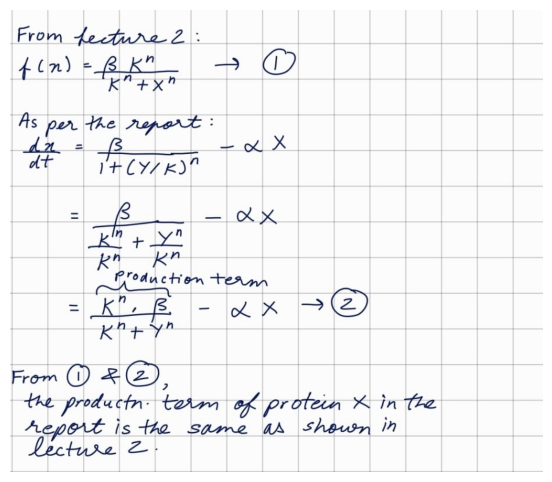

In [ ]:
#Question 1A 
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
img = mpimg.imread("images/Question1A.jpeg")
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")  # Hide axis ticks and border
plt.show()

Question 1B:


> **Units.** We measure time in units of the protein lifetime $1/\alpha$ and concentrations in
> units of $K$. In these units $\alpha = 1$ and $K = 1$, and the model reads
>
> $$\frac{dX}{dt} = \frac{\beta}{1 + Y^n} - X, \qquad \frac{dY}{dt} = \frac{\beta}{1 + X^n} - Y .$$
>
> Unless a question says otherwise, $\beta = 5$ and $n = 2$.

### Question 2
Suppose $Y$ is held at a constant value. Where does $X$ go at long times? (This is the gene of
Lecture 1.) What is this value when $Y = 0$, and when $Y$ is much larger than $1$?

**Your answer**

...

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

beta = 5.0
n = 2

---
## Part II: Fixed points

> **Nullclines: a rate plot in two dimensions.** With one gene (Lecture 3) the fixed points were
> the crossings of the production and the removal curves. With two genes we draw, in the plane
> $(X, Y)$:
> - the **X-nullcline**, the curve on which $dX/dt = 0$;
> - the **Y-nullcline**, the curve on which $dY/dt = 0$.
>
> At a point where they cross, *neither* protein changes: it is a **fixed point**.
>
> The nullclines also tell us which way the cell moves. On one side of the X-nullcline the
> production of X is larger than its removal, so $X$ increases; on the other side $X$ decreases.
> These are the arrows of a Lecture 3 rate plot, here pointing right or left. In the same way, on
> either side of the Y-nullcline $Y$ increases or decreases: the arrows point up or down. Alon draws
> the toggle switch this way in Figure 5.9.

### Question 3
(a) Write the equations of the two nullclines.
(b) Plot them on the same $(X, Y)$ plane for $\beta = 5$, $n = 2$.
(c) How many fixed points are there? Say what each one means for the phage.

**Your answer**

...

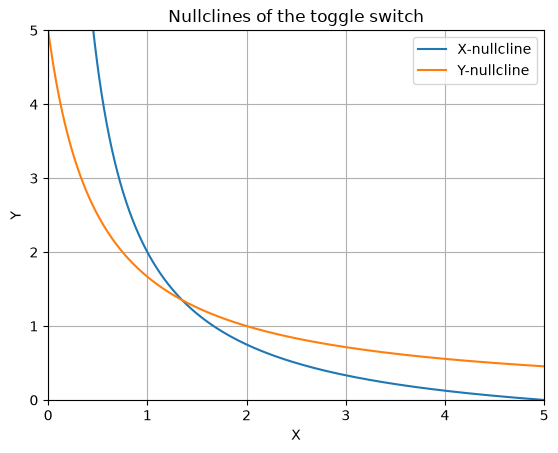

In [ ]:
# your code here
alpha = 1.0
#Question 3A
#Equation 1
def nullcline_X(Y, beta=5, K=1, n=2):
    '''Negative autoregulation, as in Lecture 2.'''
    return beta * K**n / (K**n + Y*n)

#Equation 2
def nullcline_Y(X, beta=5, K=1, n=2):
    '''Negative autoregulation, as in Lecture 2.'''
    return beta * K**n / (K**n + X*n)

# axes
X_vals = np.linspace(0, 5, 500)
Y_vals = np.linspace(0, 5, 500)

# Plotting the two curves
plt.plot(nullcline_X(Y_vals), Y_vals, label='X-nullcline')
plt.plot(X_vals, nullcline_Y(X_vals), label='Y-nullcline')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Nullclines of the toggle switch')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.legend()
plt.grid()

plt.show()


There is one fixed point, 

...

### Question 4. Back to a one-dimensional rate plot
A fixed point lies on both nullclines. Substitute the Y-nullcline into the X-nullcline, and show
that the $X$ of a fixed point solves one equation in one unknown,

$$X = F(X), \qquad F(X) = \frac{\beta}{1 + \left(\dfrac{\beta}{1+X^n}\right)^{n}} .$$

(a) Plot $F(X)$ and the straight line $X$ on the same graph, as in a Lecture 3 rate plot.
(b) Find the fixed points numerically (for instance with `brentq` between two values of $X$ that
bracket a crossing), and the corresponding $Y$. Check that they agree with Question 3.
(c) In Lecture 3 the arrows of the rate plot gave the stability of each fixed point. Can we trust
them here? Hint: what did we assume about $Y$ when we replaced it by its nullcline?

**Your answer**

...

In [ ]:
# your code here


**Your answer**

...

### Question 5. Why cooperativity matters
Repeat the plot of Question 3 for $n = 1, 2, 3$ (keeping $\beta = 5$). How does the number of
fixed points change, and why? Compare with Alon, Figure 5.10.

In [ ]:
# your code here


**Your answer**

...

---
## Part III: Dynamics, and how DNA damage flips the switch

### Question 6. Trajectories in the plane
(a) Solve the equations with `solve_ivp` from at least four initial conditions of your choice,
up to $t = 15$, and draw the trajectories on top of the nullclines. Mark the fixed points.
(b) Which fixed points are stable, which unstable? Draw the line that separates the starting
points that end in lysogeny from those that end in lysis.
(c) A phage that has just infected a cell starts with no cI and no Cro: $X = Y = 0$. Where does
the model send it? Why? Do you believe this prediction?

*Optional: add the arrows $(dX/dt, dY/dt)$ on a grid with `plt.quiver`; the picture is then what
Alon calls the phase portrait.*

In [ ]:
# your code here


**Your answer**

...

### Question 7. DNA damage
DNA damage makes RecA cleave cI, which adds a removal rate $\delta$ to $X$ while the damage lasts:

$$\frac{dX}{dt} = \frac{\beta}{1 + Y^n} - (1 + \delta)\, X, \qquad
  \frac{dY}{dt} = \frac{\beta}{1 + X^n} - Y .$$

(a) Show that with a **constant** $\delta$ the nullclines are those of a toggle without damage
whose X promoter is weaker: $\beta_X = \beta/(1+\delta)$.
(b) Plot the nullclines for a few values of $\delta$ between 0 and 1. Find (to two decimals) the
value $\delta^\ast$ above which lysogeny is no longer a fixed point. What does the phage do then?
(c) **A pulse of damage.** Start in lysogeny, apply $\delta = 1$ for a time $T$, then switch the
damage off ($\delta = 0$) and follow the cell until $t = 50$. Find (to one decimal) the shortest $T$
that sends the cell to lysis. Plot $X(t)$ and $Y(t)$ for a pulse a bit shorter and a bit longer
than that. After the damage is gone, does the cell go back to lysogeny? Compare with the memory
section of the Lecture 3 notebook.

**Your answer**

...

In [ ]:
# your code here


**Your answer**

...

In [ ]:
# your code here


**Your answer**

...

---
## Part IV: The same switch with a few molecules

> **From concentrations to molecules** (as in Lectures 2 and 4). Let $N_X$ and $N_Y$ be the
> numbers of cI and Cro molecules in one cell of volume $V$, so that $X = N_X/V$ and $Y = N_Y/V$.
> The four reactions and their rates are
>
> | reaction | change | rate |
> |---|---|---|
> | X is made | $N_X \to N_X + 1$ | $V\,\beta_X/(1 + (N_Y/V)^n)$ |
> | X is removed | $N_X \to N_X - 1$ | $(1+\delta)\, N_X$ |
> | Y is made | $N_Y \to N_Y + 1$ | $V\,\beta/(1 + (N_X/V)^n)$ |
> | Y is removed | $N_Y \to N_Y - 1$ | $N_Y$ |
>
> Production is multiplied by $V$, removal is not (first order, the same per-molecule rate in a
> large or a small cell). With $V = 10$ lysogeny holds about 48 cI molecules per cell.
> Simulate with the Gillespie algorithm.

### Question 8. One cell, and a newly infected cell
Use $V = 10$, $\beta_X = \beta = 5$ and no damage ($\delta = 0$).
(a) Simulate one cell starting from lysogeny ($N_X = 48$, $N_Y = 2$) up to $t = 100$, and plot
$N_X(t)$ and $N_Y(t)$. Does it stay in lysogeny?
(b) Now simulate a newly infected cell, $N_X = N_Y = 0$, up to $t = 100$. Repeat five times
(each run uses different random numbers) and plot $N_X - N_Y$ for the five runs on one graph.
Where does each cell go? Compare with Question 6c: what does noise do that the deterministic
model could not?

In [ ]:
# your code here


**Your answer**

...

### Question 9. How long does the memory last?
Without any damage, a lysogen occasionally switches to lysis on its own. This happens in real
lysogens too, and is called spontaneous induction. In Question 8, with $\beta = 5$, you probably
did not see it. Here we keep $V = 10$ and make both promoters weaker: $\beta = 2.5$, $3$ and $3.5$,
the same for X and Y.

For each $\beta$:
1. find the lysogenic fixed point $(X^\ast, Y^\ast)$ with your code of Question 4;
2. simulate one cell, starting from $N_X = V X^\ast$, $N_Y = V Y^\ast$ (rounded), up to
   $t = 5000$, and record $N_X$, $N_Y$ every $0.5$ time units;
3. count the switches with this rule: a lysogen has switched to lysis when $N_Y$ reaches
   $0.8\,V X^\ast$ (80% of the high level), and a lytic cell has switched back when $N_X$ does;
4. compute the **mean stay**, the mean time between two switches.

Plot the mean stay against $\beta$, with a logarithmic vertical axis. How does it change? Why does
a stronger promoter give a longer memory? (There are two reasons: think of the rate plot, and of
the number of molecules.) What does your result suggest for $\beta = 5$, and for the cell of
Question 8?

In [ ]:
# your code here


**Your answer**

...

---
## Bonus question: designing a toggle switch

*Optional: it can raise the mark, but it is not needed for full marks.*

Gardner, Cantor and Collins (2000) asked which promoter strengths give a working switch. In the
plane $(\beta_X, \beta_Y)$, between 0 and 10, colour the region where the circuit is bistable, for
$n = 2$ and for $n = 3$. Why must the two promoters be "balanced"? What does a larger $n$ buy?
Where does the damage of Question 7 move a cell in this plane?